In [2]:
# Importing Libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import re
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from itertools import combinations
from scipy.stats import norm

In [3]:
# Loading Datasets
orders = pd.read_csv("order_file.csv")
penalties = pd.read_csv("penalty_file.csv")
final_data = pd.merge(orders, penalties, on='driver.id', how='inner')

In [4]:
# Replacing dots to underscores in all columns
final_data.columns = final_data.columns.str.replace('.', '_', regex=False)
print(final_data.columns)

Index(['order_id', 'driver_id', 'business_type', 'expected_profit',
       'order_placed_time', 'delivery_completed_time', 'cancel_dummy',
       'penalty_variant'],
      dtype='object')


In [5]:
final_data.head()

,order_id,driver_id,business_type,expected_profit,order_placed_time,delivery_completed_time,cancel_dummy,penalty_variant
0,KCMXI4HAfLCjgHFR2qA1Lg==,AKTYnqStIa+/suWRUAQ60g==,grocery,12.735685,2019-05-04 14:08:33.000 America/Los_Angeles,2019-05-04 14:22:34.000 America/Los_Angeles,0,10
1,ERylrc+OvEb4gm84MxYmWQ==,ARxb2lRoxbrEgQgDEJIr7Q==,grocery,71.802685,2019-05-03 15:26:37.000 America/Los_Angeles,NaN,1,0
2,FKVvDcTRe0O1TDpg6uzLgQ==,ARxb2lRoxbrEgQgDEJIr7Q==,grocery,8.856685,2019-05-10 19:26:29.000 America/Los_Angeles,2019-05-10 19:44:22.000 America/Los_Angeles,0,0
3,ELtwBfng4uSyXpBseav1Bg==,AeWaFFe6cKFmfTEnEr6QBQ==,grocery,15.102685,2019-05-10 23:39:07.000 America/Los_Angeles,2019-05-11 00:02:06.000 America/Los_Angeles,0,0
4,OmCaoDxSXwN3nJzg8Jwamw==,Au8G9PfP3KN3SUnTPO+mMQ==,grocery,18.063685,2019-05-08 13:52:08.000 America/Los_Angeles,2019-05-08 14:18:35.000 America/Los_Angeles,0,0


## DATA VISUALISATION

In [7]:
# Unique driver IDs
unique_driver_ids = final_data['driver_id'].unique()
num_unique_drivers = len(unique_driver_ids)
print(f"Number of unique drivers: {num_unique_drivers}")
print("\n")

# NaN values per column
nan_counts = final_data.isna().sum()
print("Number of NaN values in each column:")
print(nan_counts)
print("\n")

# Statistics for the dataset
mean_expected_profit = final_data['expected_profit'].mean()
median_expected_profit = final_data['expected_profit'].median()
print("Mean of expected profit",mean_expected_profit )
print("Median of expected profit",median_expected_profit)
print("Max value of expected profit", max(final_data['expected_profit']))

Number of unique drivers: 397947


Number of NaN values in each column:
order_id                        0
driver_id                       0
business_type                   0
expected_profit              3735
order_placed_time               0
delivery_completed_time    155486
cancel_dummy                    0
penalty_variant                 0
dtype: int64


Mean of expected profit 14.47974263182338
Median of expected profit 11.23268526
Max value of expected profit 568.0896853


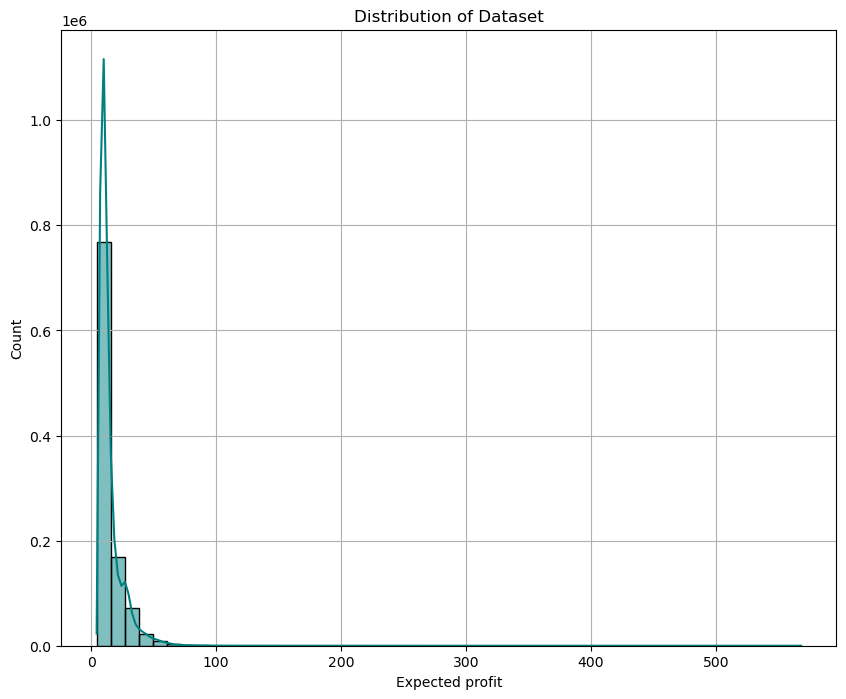

In [8]:
#Distribution Plot for the Dataset - Histogram
plt.figure(figsize=(10,8))
sns.histplot(final_data['expected_profit'], kde=True, bins = 50, color = 'teal') 
plt.title('Distribution of Dataset')
plt.xlabel('Expected profit')
plt.grid()
plt.show()

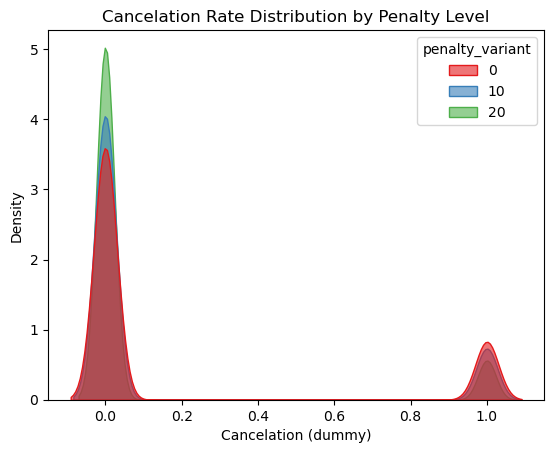

In [9]:
# Cancelation Rate Distribution across penalties - KDE Plot
sns.kdeplot(data=final_data, x='cancel_dummy', hue='penalty_variant', fill=True, alpha=0.6, palette="Set1")
plt.title('Cancelation Rate Distribution by Penalty Level')
plt.xlabel('Cancelation (dummy)')
plt.ylabel('Density')
plt.show()

In [10]:
# Fixing the date-time format in the Dataset
# Define the cleaning function
def clean_datetime(value):
    if isinstance(value, str):
        # Remove timezone or extra characters
        value = re.sub(r' [A-Za-z/_]+', '', value)
    return value

# Apply cleaning function
final_data['order_placed_time'] = final_data['order_placed_time'].apply(clean_datetime)

# Convert to datetime format
final_data['order_placed_time'] = pd.to_datetime(final_data['order_placed_time'])

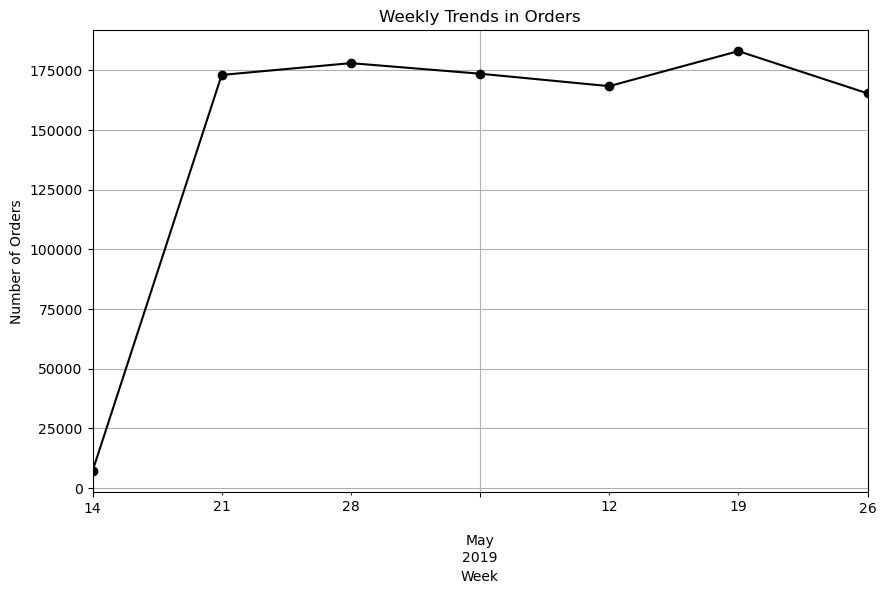

In [11]:
# Weekly Trends in Orders - Line Graph
# Resampling 
weekly_orders = final_data.resample('W', on='order_placed_time').size()

# Plot 
plt.figure(figsize=(10, 6))
weekly_orders.plot(kind='line', marker='o', color = 'black')
plt.title('Weekly Trends in Orders')
plt.xlabel('Week')
plt.ylabel('Number of Orders')
plt.grid()
plt.show()

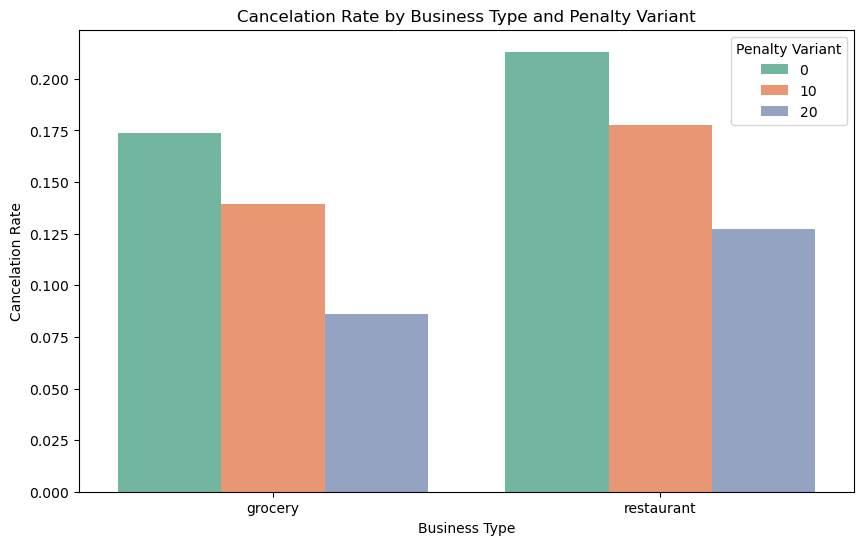

In [12]:
# Cancelation Rate by Business Type - Bar Plot
# Group by business.type and penalty.variant, calculate average cancellation rates
cancellation_rates = final_data.groupby(['business_type', 'penalty_variant'])['cancel_dummy'].mean().reset_index()

#Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=cancellation_rates, x='business_type', y='cancel_dummy', hue='penalty_variant', palette='Set2')
plt.title('Cancelation Rate by Business Type and Penalty Variant')
plt.xlabel('Business Type')
plt.ylabel('Cancelation Rate')
plt.legend(title='Penalty Variant')
plt.show()

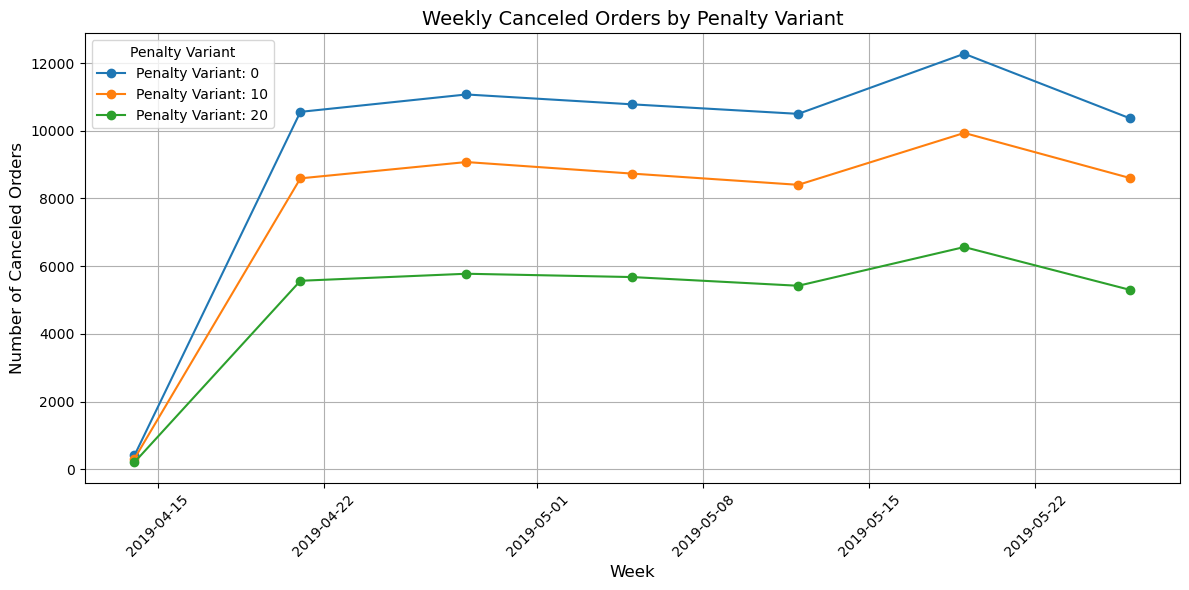

In [13]:
# Weekly Canceled Orders - Line Graph
# Convert 'order_placed_time' to datetime and set as index
final_data['order_placed_time'] = pd.to_datetime(final_data['order_placed_time'])
final_data.set_index('order_placed_time', inplace=True)

# Resample by week 
weekly_cancelation = (
    final_data.groupby('penalty_variant')
    .resample('W')['cancel_dummy']
    .sum()
    .reset_index()
    .rename(columns={'cancel_dummy': 'weekly_cancelations'})
)

# Pivot the Data 
weekly_cancelation_pivot = weekly_cancelation.pivot(index='order_placed_time', columns='penalty_variant', values='weekly_cancelations')

# Plot
plt.figure(figsize=(12, 6))
for penalty_variant in weekly_cancelation_pivot.columns:
    plt.plot(
        weekly_cancelation_pivot.index,
        weekly_cancelation_pivot[penalty_variant],
        marker='o',
        label=f'Penalty Variant: {penalty_variant}',)

plt.title('Weekly Canceled Orders by Penalty Variant', fontsize=14)
plt.xlabel('Week', fontsize=12)
plt.ylabel('Number of Canceled Orders', fontsize=12)
plt.legend(title="Penalty Variant")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# HYPOTHESES

## 1. This analysis evaluates **whether penalties impact the number of completed orders per driver**, considering the distribution across different penalty levels.

-**Null Hypothesis (H0)**: The average number of completed orders per driver does not differ significantly across the three penalty variants.

-**Alternative Hypothesis (Ha)**: The average number of completed orders per driver differs significantly across the three penalty variants.

In [16]:
# Data Manipulation 
completed_orders = final_data[final_data['cancel_dummy'] == 0]
completed_orders_per_driver = completed_orders.groupby(['penalty_variant', 'driver_id']).size().reset_index(name='completed_orders')

# ANOVA
completed_orders_per_driver['penalty_variant'] = completed_orders_per_driver['penalty_variant'].astype('category')
model = ols('completed_orders ~ C(penalty_variant)', data=completed_orders_per_driver).fit()
anova_result = sm.stats.anova_lm(model, typ=2)

# p-value
p_value = anova_result['PR(>F)'].iloc[0]
alpha = 0.05  
print(f"P-Value for ANOVA test: {p_value}")

# Conclusion
if p_value < alpha:
    print(f"The null hypothesis is rejected.")
    print("Conclusion: There is a significant difference in the mean number of completed orders across penalty variants.")
else:
    print(f"The null hypothesis is not rejected.")
    print("Conclusion: There is no significant difference in the mean number of completed orders across penalty variants.")

P-Value for ANOVA test: 1.1186273905673488e-06
The null hypothesis is rejected.
Conclusion: There is a significant difference in the mean number of completed orders across penalty variants.


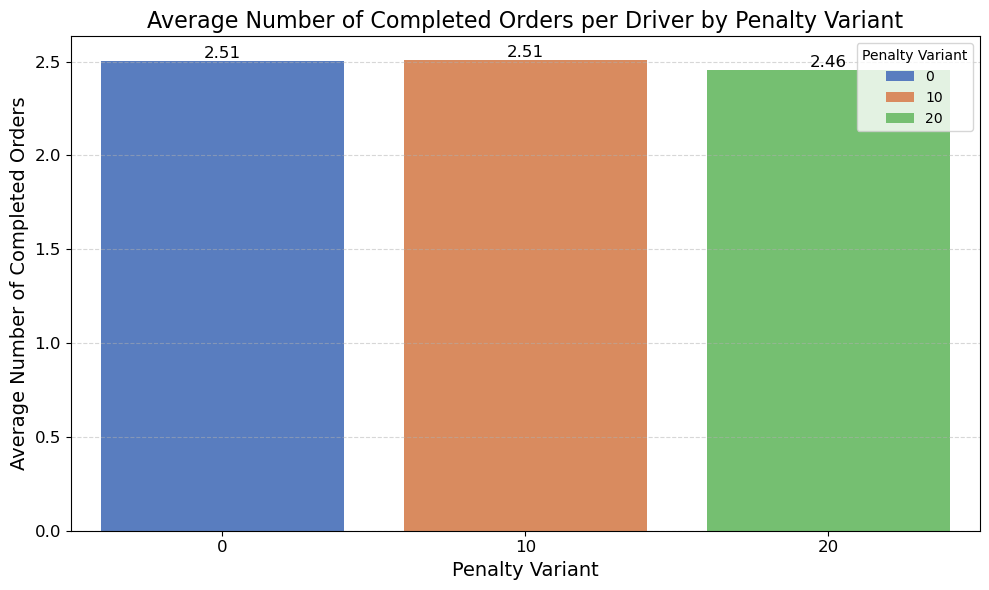

In [17]:
# Visualisation for the ANOVA test
# Calculate mean completed orders per driver for each penalty variant
mean_completed_orders_per_variant = completed_orders_per_driver.groupby(
    'penalty_variant', observed=False)['completed_orders'].mean().reset_index()

# Plot
plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(
    x='penalty_variant',
    y='completed_orders',
    data=mean_completed_orders_per_variant,
    palette='muted',
    hue='penalty_variant'
)

plt.title('Average Number of Completed Orders per Driver by Penalty Variant', fontsize=16)
plt.xlabel('Penalty Variant', fontsize=14)
plt.ylabel('Average Number of Completed Orders', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

for p in bar_plot.patches:
    height = p.get_height()
    if height > 0.01:  
        bar_plot.annotate(f'{height:.2f}',
                          (p.get_x() + p.get_width() / 2., height),
                          ha='center', va='bottom', fontsize=12, color='black')

plt.tight_layout()
plt.legend(title='Penalty Variant')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


#### Multiple Testing between the three penalty varients for above hypothesis:

In [19]:
# Data Manipulation
data_0 = completed_orders_per_driver[completed_orders_per_driver['penalty_variant'] == 0]['completed_orders']
data_10 = completed_orders_per_driver[completed_orders_per_driver['penalty_variant'] == 10]['completed_orders']
data_20 = completed_orders_per_driver[completed_orders_per_driver['penalty_variant'] == 20]['completed_orders']

# Welch's t-tests 
# Test 0 vs 10
t_stat_01, p_value_01 = ttest_ind(data_0, data_10, equal_var=False)

# Test 0 vs 20
t_stat_02, p_value_02 = ttest_ind(data_0, data_20, equal_var=False)

# Test 10 vs 20
t_stat_12, p_value_12 = ttest_ind(data_10, data_20, equal_var=False)

t_stats = [t_stat_01, t_stat_02, t_stat_12]
p_values = [p_value_01, p_value_02, p_value_12]
print(f"T-Statistics: {t_stats}")
print(f"\nP-Values: {p_values}")

# Bonferroni Corrections
alpha = 0.05 / len(p_values)
adjusted_p_values = multipletests(p_values, method='bonferroni')[1]
p_value_01b, p_value_02b, p_value_12b = adjusted_p_values
print(f"\nBonferroni Adjusted P-Values: {adjusted_p_values}")

# Conclusions
if p_value_01b < alpha:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThe mean number of completed orders per driver is significantly different between penalty variants 0 and 10.")
else:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThere is no significant difference in the mean number of completed orders per driver between penalty variants 0 and 10.")

if p_value_02b < alpha:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThe mean number of completed orders per driver is significantly different between penalty variants 0 and 20.")
else:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThere is no significant difference in the mean number of completed orders per driver between penalty variants 0 and 20.")

if p_value_12b < alpha:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThe mean number of completed orders per driver is significantly different between penalty variants 10 and 20.")
else:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThere is no significant difference in the mean number of completed orders per driver between penalty variants 10 and 20.")

T-Statistics: [-0.3025466457982164, 4.340865959390602, 4.71420117325977]

P-Values: [0.7622356506322779, 1.4198158878815154e-05, 2.4279585979579413e-06]

Bonferroni Adjusted P-Values: [1.00000000e+00 4.25944766e-05 7.28387579e-06]

P-Value for penalty variants 0 and 10: 1.0.
There is no significant difference in the mean number of completed orders per driver between penalty variants 0 and 10.

P-Value for penalty variants 0 and 20: 4.259447663644546e-05.
The mean number of completed orders per driver is significantly different between penalty variants 0 and 20.

P-Value for penalty variants 10 and 20: 7.283875793873823e-06.
The mean number of completed orders per driver is significantly different between penalty variants 10 and 20.


## 2. This analysis evaluates **whether penalty variants impact the mean number of canceled orders per driver**.

-**Null Hypothesis (H0)**:
The mean number of canceled orders per driver is the same across the different penalty variants.

-**Alternative Hypothesis (Ha)**:
The mean number of canceled orders per driver differs significantly across the different penalty variants.

In [21]:
# Data Manipulation
canceled_orders = final_data[final_data['cancel_dummy'] == 1]
canceled_orders_per_driver = canceled_orders.groupby(['penalty_variant', 'driver_id']).size().reset_index(name='canceled_orders')

# ANOVA
# Ensure penalty_variant is treated as a categorical variable
canceled_orders_per_driver['penalty_variant'] = canceled_orders_per_driver['penalty_variant'].astype('category')
canceled_orders_per_driver.rename(columns={'penalty_variant': 'penalty_variant'}, inplace=True)
model = ols('canceled_orders ~ C(penalty_variant)', data=canceled_orders_per_driver).fit()
anova_result = sm.stats.anova_lm(model, typ=2)

# p-value 
p_value_anova = anova_result['PR(>F)'].iloc[0]
alpha = 0.05 
print(f"P-Value for ANOVA test: {p_value}")

# Conclusion
if p_value_anova < alpha:
    print("The null hypothesis is rejected.")
    print("Conclusion: There is a significant difference in the mean number of canceled orders across penalty variants.")
else:
    print("The null hypothesis is not rejected.")
    print("Conclusion: There is no significant difference in the mean number of canceled orders across penalty variants.")

P-Value for ANOVA test: 1.1186273905673488e-06
The null hypothesis is rejected.
Conclusion: There is a significant difference in the mean number of canceled orders across penalty variants.


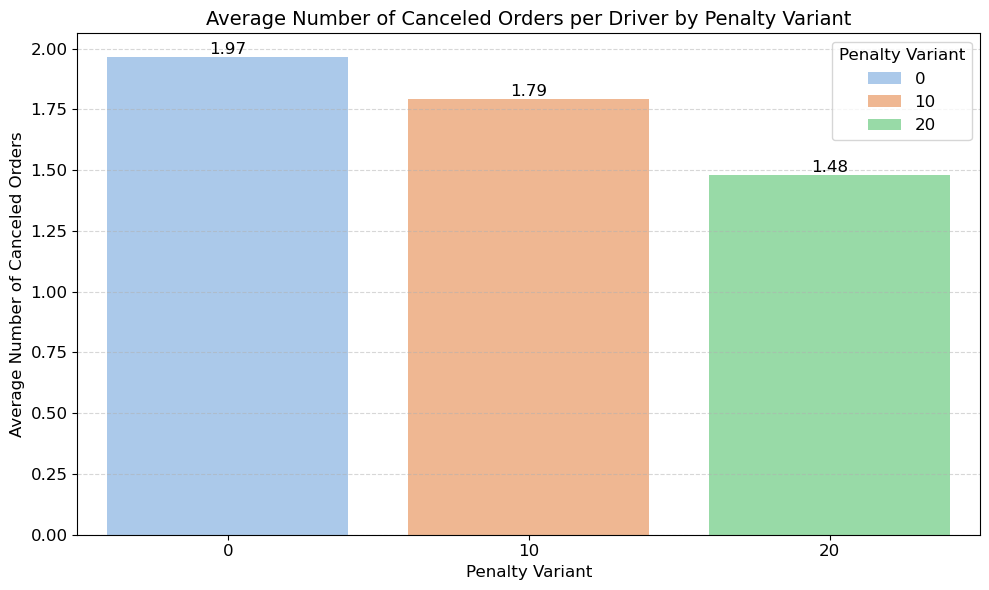

In [22]:
# Visualisation for the ANOVA test
# Calculate the mean number of canceled orders per driver for each penalty variant
mean_canceled_orders_per_variant = canceled_orders_per_driver.groupby(
    'penalty_variant', observed=False)['canceled_orders'].mean().reset_index()

# Plot
plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(
    x='penalty_variant',
    y='canceled_orders',
    data=mean_canceled_orders_per_variant,
    palette='pastel',
    hue='penalty_variant')

plt.title('Average Number of Canceled Orders per Driver by Penalty Variant', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Average Number of Canceled Orders', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

for p in bar_plot.patches:
    height = p.get_height()
    if height > 0.01:  
        bar_plot.annotate(f'{height:.2f}',
                          (p.get_x() + p.get_width() / 2., height),
                          ha='center', va='bottom', fontsize=12, color='black')

plt.tight_layout()
plt.legend(title='Penalty Variant', fontsize=12, title_fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [23]:
# Confidence Interval 
# Calculate the number of canceled orders per driver for each penalty variant
canceled_orders = final_data[final_data['cancel_dummy'] == 1]
canceled_orders_per_driver = (
    canceled_orders.groupby(['penalty_variant', 'driver_id'])
    .size()
    .reset_index(name='canceled_orders')
)

# Calculate mean, std, and SEM 
ci_data_canceled = (
    canceled_orders_per_driver.groupby('penalty_variant')['canceled_orders']
    .agg(['mean', 'std', 'count'])  # Calculate mean, std, and count
    .reset_index()
)

# Add SEM
ci_data_canceled['sem'] = ci_data_canceled['std'] / np.sqrt(ci_data_canceled['count'])

# Calculate 95% confidence interval
z = 1.96 
ci_data_canceled['ci_lower'] = ci_data_canceled['mean'] - z * ci_data_canceled['sem']
ci_data_canceled['ci_upper'] = ci_data_canceled['mean'] + z * ci_data_canceled['sem']

print(ci_data_canceled[['penalty_variant', 'mean', 'ci_lower', 'ci_upper']])

   penalty_variant      mean  ci_lower  ci_upper
0                0  1.965057  1.940056  1.990058
1               10  1.793756  1.771184  1.816328
2               20  1.482261  1.467320  1.497202


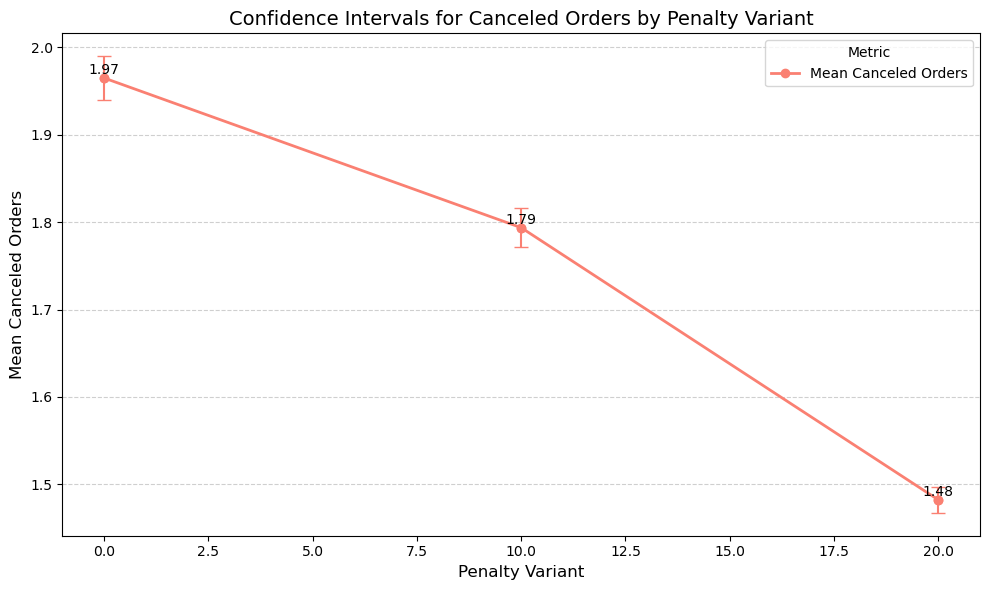

In [24]:
# Visualization for Canceled Orders Confidence Intervals - Line Graph
# Data Preparation
ci_data_canceled = ci_data_canceled.sort_values('penalty_variant')
penalty_variants = ci_data_canceled['penalty_variant']
means = ci_data_canceled['mean']
ci_lower = ci_data_canceled['ci_lower']
ci_upper = ci_data_canceled['ci_upper']
errors = [means - ci_lower, ci_upper - means]  # Error bars

# Plot
plt.figure(figsize=(10, 6))
plt.plot(
    penalty_variants, 
    means, 
    marker='o', 
    linestyle='-', 
    color='salmon', 
    label='Mean Canceled Orders', 
    linewidth=2)

plt.errorbar(
    penalty_variants, 
    means, 
    yerr=errors, 
    fmt='o', 
    color='salmon', 
    capsize=5, 
    elinewidth=1.5)

for x, y in zip(penalty_variants, means):
    plt.text(
        x, 
        y + max(errors[1]) * 0.05, 
        f'{y:.2f}', 
        ha='center', 
        va='bottom', 
        fontsize=10)

plt.title('Confidence Intervals for Canceled Orders by Penalty Variant', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Mean Canceled Orders', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Metric', loc='best')
plt.tight_layout()
plt.show()

#### Multiple Testing between the three penalty varients for above hypothesis:

In [26]:
# Data Manipulation
data_0 = canceled_orders_per_driver[canceled_orders_per_driver['penalty_variant'] == 0]['canceled_orders']
data_10 = canceled_orders_per_driver[canceled_orders_per_driver['penalty_variant'] == 10]['canceled_orders']
data_20 = canceled_orders_per_driver[canceled_orders_per_driver['penalty_variant'] == 20]['canceled_orders']

# Welch's t-tests 
# Test 1: 0 vs 10
t_stat_01, p_value_01 = ttest_ind(data_0, data_10, equal_var=False)

# Test 2: 0 vs 20
t_stat_02, p_value_02 = ttest_ind(data_0, data_20, equal_var=False)

# Test 3: 10 vs 20
t_stat_12, p_value_12 = ttest_ind(data_10, data_20, equal_var=False)

t_stats = [t_stat_01, t_stat_02, t_stat_12]
p_values = [p_value_01, p_value_02, p_value_12]
print(f"T-Statistics: {t_stats}")
print(f"\nP-Values: {p_values}")


#Bonferroni Corrections
alpha = 0.05 / len(p_values)
adjusted_p_values = multipletests(p_values, method='bonferroni')[1]
p_value_01b, p_value_02b, p_value_12b = adjusted_p_values
print(f"\nBonferroni Adjusted P-Values: {adjusted_p_values}")

# Conclusions
if p_value_01b < alpha:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThe mean number of canceled orders per driver is significantly different between penalty variants.")
else:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThere is no significant difference in the mean number of canceled orders per driver between penalty variants.")

if p_value_02b < alpha:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThe mean number of canceled orders per driver is significantly different between penalty variants 0 and 20.")
else:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThere is no significant difference in the mean number of canceled orders per driver between penalty variants.")

if p_value_12b < alpha:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThe mean number of canceled orders per driver is significantly different between penalty variants.")
else:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThere is no significant difference in the mean number of canceled orders per driver between penalty variants.")

T-Statistics: [9.967887026445524, 32.489948028258475, 22.5548290623533]

P-Values: [2.191927319841795e-23, 2.8850574984957853e-229, 4.417534203032255e-112]

Bonferroni Adjusted P-Values: [6.57578196e-023 8.65517250e-229 1.32526026e-111]

P-Value for penalty variants 0 and 10: 6.575781959525385e-23.
The mean number of canceled orders per driver is significantly different between penalty variants.

P-Value for penalty variants 0 and 20: 8.655172495487356e-229.
The mean number of canceled orders per driver is significantly different between penalty variants 0 and 20.

P-Value for penalty variants 10 and 20: 1.3252602609096764e-111.
The mean number of canceled orders per driver is significantly different between penalty variants.


## This analysis evaluates **whether penalty variants impact the revenue per driver**.

-**Null Hypothesis (H0)**: The revenue per driver is the same across the different penalty variants.

-**Alternative Hypothesis (Ha)**: The revenue per driver differs significantly across at least one of the penalty variants.

In [28]:
# Data Manipulation
final_data['revenue'] = final_data.apply(
    lambda row: row['expected_profit'] if row['cancel_dummy'] == 0 else row['penalty_variant'] / 2, axis=1
)
revenue_per_driver = final_data.groupby(['penalty_variant', 'driver_id'])['revenue'].sum().reset_index()

# ANOVA
revenue_per_driver['penalty_variant'] = revenue_per_driver['penalty_variant'].astype('category')
model_revenue = ols('revenue ~ C(penalty_variant)', data=revenue_per_driver).fit()
anova_result_revenue = sm.stats.anova_lm(model_revenue, typ=2)

# p-value
p_value_revenue_anova = anova_result_revenue['PR(>F)'].iloc[0]
alpha = 0.05
print(f"P-Value for ANOVA test on revenue: {p_value_revenue_anova}")

# Conclusion
if p_value_revenue_anova < alpha:
    print("The null hypothesis is rejected.")
    print("Conclusion: There is a significant difference in the revenue per driver across penalty variants.")
else:
    print("The null hypothesis is not rejected.")
    print("Conclusion: There is no significant difference in the revenue per driver across penalty variants.")

P-Value for ANOVA test on revenue: 9.362265128788565e-291
The null hypothesis is rejected.
Conclusion: There is a significant difference in the revenue per driver across penalty variants.


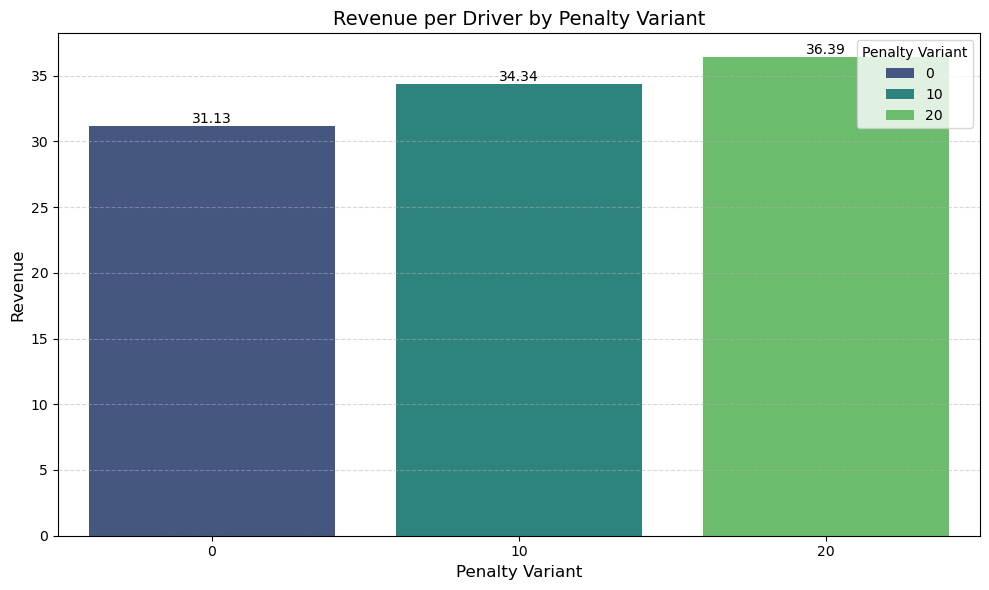

In [29]:
# Visualisation for the ANOVA test
# Calculate mean revenue per penalty variant for plotting
mean_revenue_per_variant = revenue_per_driver.groupby(
    'penalty_variant', observed=False)['revenue'].mean().reset_index()

# Plot
plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(
    data=mean_revenue_per_variant, 
    x='penalty_variant', 
    y='revenue', 
    palette='viridis', 
    hue='penalty_variant')

for p in bar_plot.patches:
    height = p.get_height()
    if height > 0.01:  
        bar_plot.annotate(f'{height:.2f}', 
                          (p.get_x() + p.get_width() / 2., height), 
                          ha='center', va='bottom', fontsize=10)

plt.title('Revenue per Driver by Penalty Variant', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Revenue', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.legend(title='Penalty Variant')
plt.show()

In [30]:
# Confidence Interval
# Data Manipulation 
final_data['revenue'] = final_data.apply(
    lambda row: row['expected_profit'] if row['cancel_dummy'] == 0 else row['penalty_variant'] / 2, axis=1
)

revenue_per_driver = final_data.groupby(['penalty_variant', 'driver_id'])['revenue'].sum().reset_index()

# Calculate mean, std, and SEM 
ci_data_revenue = (
    revenue_per_driver.groupby('penalty_variant')['revenue']
    .agg(['mean', 'std', 'count'])  # Calculate mean, standard deviation, and count
    .reset_index()
)

# Add SEM
ci_data_revenue['sem'] = ci_data_revenue['std'] / np.sqrt(ci_data_revenue['count'])

# Calculate 95% confidence intervals
z = 1.96  # For a 95% confidence level
ci_data_revenue['ci_lower'] = ci_data_revenue['mean'] - z * ci_data_revenue['sem']
ci_data_revenue['ci_upper'] = ci_data_revenue['mean'] + z * ci_data_revenue['sem']

print(ci_data_revenue[['penalty_variant', 'mean', 'ci_lower', 'ci_upper']])

   penalty_variant       mean   ci_lower   ci_upper
0                0  31.132508  30.932386  31.332630
1               10  34.342425  34.140303  34.544548
2               20  36.394948  36.194270  36.595627


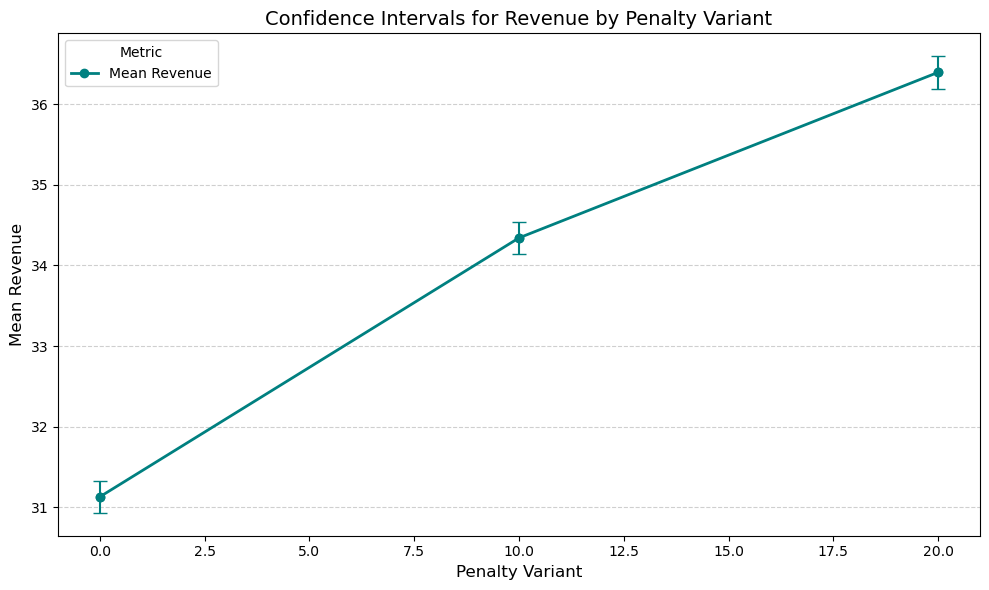

In [31]:
# Visualization for Revenue Confidence Intervals - Line Graph
# Data Preparation
ci_data_revenue = ci_data_revenue.sort_values('penalty_variant')
penalty_variants = ci_data_revenue['penalty_variant']
means = ci_data_revenue['mean']
ci_lower = ci_data_revenue['ci_lower']
ci_upper = ci_data_revenue['ci_upper']
errors = [means - ci_lower, ci_upper - means]

# Plot
plt.figure(figsize=(10, 6))
plt.plot(
    penalty_variants, 
    means, 
    marker='o', 
    linestyle='-', 
    color='teal', 
    label='Mean Revenue', 
    linewidth=2)

plt.errorbar(
    penalty_variants, 
    means, 
    yerr=errors, 
    fmt='o', 
    color='teal', 
    capsize=5, 
    elinewidth=1.5)

plt.title('Confidence Intervals for Revenue by Penalty Variant', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Mean Revenue', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.legend(title='Metric', loc='best')
plt.tight_layout()
plt.show()


#### Multiple Testing between the three penalty varients for above hypothesis:

In [33]:
# Data Manipulation
data_0 = revenue_per_driver[revenue_per_driver['penalty_variant'] == 0]['revenue']
data_10 = revenue_per_driver[revenue_per_driver['penalty_variant'] == 10]['revenue']
data_20 = revenue_per_driver[revenue_per_driver['penalty_variant'] == 20]['revenue']

# Welch's t-tests 
# Test 1: 0 vs 10
t_stat_01, p_value_01 = ttest_ind(data_0, data_10, equal_var=False)

# Test 2: 0 vs 20
t_stat_02, p_value_02 = ttest_ind(data_0, data_20, equal_var=False)

# Test 3: 10 vs 20
t_stat_12, p_value_12 = ttest_ind(data_10, data_20, equal_var=False)

t_stats = [t_stat_01, t_stat_02, t_stat_12]
p_values = [p_value_01, p_value_02, p_value_12]
print(f"T-Statistics: {t_stats}")
print(f"\nP-Values: {p_values}")

# Bonferroni Corrections
alpha = 0.05 / len(p_values)
adjusted_p_values = multipletests(p_values, method='bonferroni')[1]
p_value_01b, p_value_02b, p_value_12b = adjusted_p_values
print(f"\nBonferroni Adjusted P-Values: {adjusted_p_values}")

# Conclusions
if p_value_01b < alpha:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThe mean revenue per driver is significantly different between penalty variants.")
else:
    print(f"\nP-Value for penalty variants 0 and 10: {p_value_01b}.\nThere is no significant difference in the mean revenue per driver between penalty variants.")

if p_value_02b < alpha:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThe mean revenue per driver is significantly different between penalty variants.")
else:
    print(f"\nP-Value for penalty variants 0 and 20: {p_value_02b}.\nThere is no significant difference in the mean revenue per driver between penalty variants.")

if p_value_12b < alpha:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThe mean revenue per driver is significantly different between penalty variants.")
else:
    print(f"\nP-Value for penalty variants 10 and 20: {p_value_12b}.\nThere is no significant difference in the mean revenue per driver between penalty variants.")

T-Statistics: [-22.119214257849016, -36.393947690916455, -14.12427093917768]

P-Values: [2.5892086144685215e-108, 2.7647413189852798e-289, 2.7955508518268844e-45]

Bonferroni Adjusted P-Values: [7.76762584e-108 8.29422396e-289 8.38665256e-045]

P-Value for penalty variants 0 and 10: 7.767625843405564e-108.
The mean revenue per driver is significantly different between penalty variants.

P-Value for penalty variants 0 and 20: 8.29422395695584e-289.
The mean revenue per driver is significantly different between penalty variants.

P-Value for penalty variants 10 and 20: 8.386652555480653e-45.
The mean revenue per driver is significantly different between penalty variants.


## Linear Regression for Cancelled Orders

                          coef    std err          t   P>|t|     [0.025  \
0            const      0.9571      0.002    481.752   0.000      0.953   
1  penalty_variant     -0.0050      0.000    -29.906   0.000     -0.005   

      0.975]  
0      0.961  
1     -0.005  

Predicted Canceled Orders per Penalty Variant:
penalty_variant
0    1.60409357222451109948
10   1.47735948640367276141
20   1.35679320064968189641
Name: predicted_canceled_orders, dtype: float64

Interpretation:
A negative coefficient for 'penalty variant' suggests that as the penalty increases, the number of canceled orders tends to decrease.


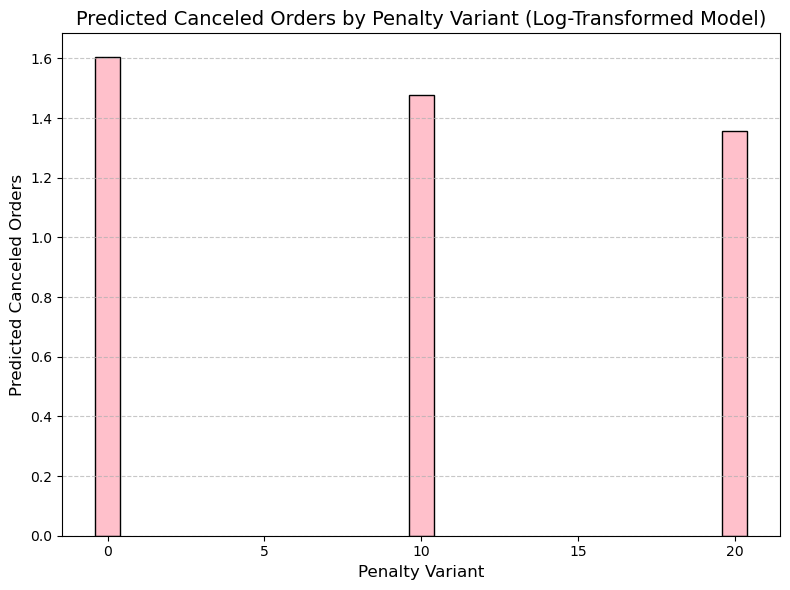

In [35]:
# Data Manipulation
canceled_orders = final_data[final_data['cancel_dummy'] == 1]
canceled_orders_per_driver = canceled_orders.groupby(['penalty_variant', 'driver_id']).size().reset_index(name='canceled_orders')

# Apply log transformation on 'canceled_orders'
canceled_orders_per_driver['log_canceled_orders'] = np.log(canceled_orders_per_driver['canceled_orders'] + 1)

# Data Preparation
X = canceled_orders_per_driver[['penalty_variant']].copy()  # Independent variable
y = canceled_orders_per_driver['log_canceled_orders']  # Log-transformed dependent variable

X_sm = sm.add_constant(X)

# Model Fitting
linear_model_sm = sm.OLS(y, X_sm).fit()
y_pred_log = linear_model_sm.predict(X_sm)

# Convert to original-scale
y_pred_original = np.exp(y_pred_log) - 1  # Apply exponential and subtract 1

# Model Evaluation
mse_log = mean_squared_error(y, y_pred_log)
mse_original = mean_squared_error(canceled_orders_per_driver['canceled_orders'], y_pred_original)

# Display Results
summary_table = linear_model_sm.summary().tables[1]
data = summary_table.data[1:] 
columns = summary_table.data[0] 
coefficients_df = pd.DataFrame(data, columns=columns)
pd.set_option('display.float_format', '{:.20f}'.format)  
print(coefficients_df)
canceled_orders_per_driver['predicted_canceled_orders'] = y_pred_original
average_canceled_orders_per_penalty = canceled_orders_per_driver.groupby('penalty_variant')['predicted_canceled_orders'].mean()
print("\nPredicted Canceled Orders per Penalty Variant:")
print(average_canceled_orders_per_penalty)

penalty_variant_coefficient = float(coefficients_df.loc[1, 'coef'])

print("\nInterpretation:")
if penalty_variant_coefficient > 0:
    print("A positive coefficient for 'penalty variant' suggests that as the penalty increases, the number of canceled orders tends to increase.")
else:
    print("A negative coefficient for 'penalty variant' suggests that as the penalty increases, the number of canceled orders tends to decrease.")


# Visualization - Bar Graph
plt.figure(figsize=(8, 6))
plt.bar(
    average_canceled_orders_per_penalty.index,
    average_canceled_orders_per_penalty.values,
    color='pink',
    edgecolor='black'
)
plt.title('Predicted Canceled Orders by Penalty Variant (Log-Transformed Model)', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Predicted Canceled Orders', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Linear Regression for Revenue

Linear Regression Coefficients (Log Scale): {'penalty_variant': 0.022756589869682514}
Intercept (Log Scale): 2.867247459460746
Mean Squared Error (Log Scale): 1.074173572955966
Mean Squared Error (Original Scale): 1554.9599259974111

Predicted Revenue per Penalty Variant (Original Scale):
penalty_variant
0    16.58853834424352413635
10   21.08311651933331276609
20   26.72623999003631922733
Name: predicted_revenue, dtype: float64

Interpretation:
A positive coefficient for 'penalty_variant' suggests that as the penalty increases, the total revenue tends to increase.


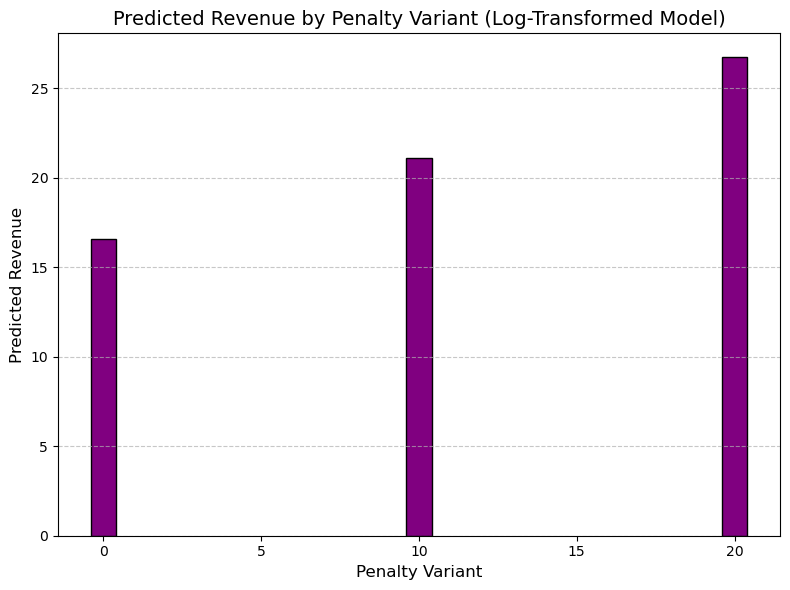

In [37]:
# Data Manipulation
final_data['revenue'] = final_data.apply(
    lambda row: row['expected_profit'] if row['cancel_dummy'] == 0 else row['penalty_variant'] / 2, axis=1
)
revenue_per_driver = final_data.groupby(['penalty_variant', 'driver_id'])['revenue'].sum().reset_index()

# Apply log transformation on 'revenue'
revenue_per_driver['log_revenue'] = np.log(revenue_per_driver['revenue'] + 1)

# Data Preparation 
X = revenue_per_driver[['penalty_variant']].copy()  # Independent variable
y = revenue_per_driver['log_revenue']  # Log-transformed dependent variable
X['penalty_variant'] = pd.to_numeric(X['penalty_variant'], errors='coerce')

# Model Fitting
linear_model = LinearRegression()
linear_model.fit(X, y)
coefficients = dict(zip(X.columns, linear_model.coef_))
intercept = linear_model.intercept_
y_pred_log = linear_model.predict(X)

# Convert to original-scale
y_pred_original = np.exp(y_pred_log) - 1  # Apply exponential and subtract 1

# Model Evaluation
mse_log = mean_squared_error(y, y_pred_log)
mse_original = mean_squared_error(revenue_per_driver['revenue'], y_pred_original)

# Display results
print("Linear Regression Coefficients (Log Scale):", coefficients)
print("Intercept (Log Scale):", intercept)
print("Mean Squared Error (Log Scale):", mse_log)
print("Mean Squared Error (Original Scale):", mse_original)
revenue_per_driver['predicted_revenue'] = y_pred_original
average_revenue_per_penalty = revenue_per_driver.groupby('penalty_variant')['predicted_revenue'].mean()
print("\nPredicted Revenue per Penalty Variant (Original Scale):")
print(average_revenue_per_penalty)
print("\nInterpretation:")
if coefficients['penalty_variant'] > 0:
    print("A positive coefficient for 'penalty_variant' suggests that as the penalty increases, the total revenue tends to increase.")
else:
    print("A negative coefficient for 'penalty_variant' suggests that as the penalty increases, the total revenue tends to decrease.")

# Visualization - Bar Graph
plt.figure(figsize=(8, 6))
plt.bar(
    average_revenue_per_penalty.index,
    average_revenue_per_penalty.values,
    color='purple',
    edgecolor='black'
)
plt.title('Predicted Revenue by Penalty Variant (Log-Transformed Model)', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Predicted Revenue', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [38]:
# Data Manipulation
average_revenue_per_penalty = revenue_per_driver.groupby('penalty_variant')['revenue'].mean()
average_canceled_orders_per_penalty = canceled_orders_per_driver.groupby('penalty_variant')['canceled_orders'].mean()
combined_metrics = pd.DataFrame({
    'penalty_variant': average_revenue_per_penalty.index,
    'avg_revenue': average_revenue_per_penalty.values,
    'avg_canceled_orders': average_canceled_orders_per_penalty.values
})
print(combined_metrics)

# Z-Score Normalization
def z_score(series):
    return (series - series.mean()) / series.std()
combined_metrics['z_score_revenue'] = z_score(combined_metrics['avg_revenue'])
combined_metrics['z_score_canceled_orders'] = z_score(combined_metrics['avg_canceled_orders'])

# Calculate Composite Score
weight_revenue = 0.5
weight_canceled_orders = 0.5

combined_metrics['composite_score'] = (
    weight_revenue * combined_metrics['z_score_revenue'] -
    weight_canceled_orders * combined_metrics['z_score_canceled_orders']
)

# Optimal Penalty Variant
optimal_penalty = combined_metrics.loc[combined_metrics['composite_score'].idxmax()]

# Display Results

print("\nOptimal Penalty Variant:")
print("\nCombined Metrics (with Z-Score Normalization):")
print(combined_metrics)
print(optimal_penalty)

print("\nInterpretation:")
if optimal_penalty['composite_score'] > 0:
    print("The penalty variant with the highest composite score indicates that it strikes the best balance between revenue maximization and minimizing canceled orders.")
else:
    print("The penalty variant with the highest composite score suggests that it may be optimal for balancing revenue and canceled orders, but further analysis might be required to confirm its effectiveness.")

   penalty_variant             avg_revenue    avg_canceled_orders
0                0 31.13250811229560710558 1.96505704667997260771
1               10 34.34242545175692384873 1.79375584971252832744
2               20 36.39494846907408032166 1.48226097414311475120

Optimal Penalty Variant:

Combined Metrics (with Z-Score Normalization):
   penalty_variant             avg_revenue    avg_canceled_orders  \
0                0 31.13250811229560710558 1.96505704667997260771   
1               10 34.34242545175692384873 1.79375584971252832744   
2               20 36.39494846907408032166 1.48226097414311475120   

          z_score_revenue  z_score_canceled_orders         composite_score  
0 -1.06476196276970291876   0.89077552792484948618 -0.97776874534727620247  
1  0.14545531413193937831   0.19092129548719152798 -0.02273299067762607484  
2  0.91930664863775946039  -1.08169682341204009823  1.00050173602489977931  
penalty_variant           20.00000000000000000000
avg_revenue               3

### Long Term Analysis

In [40]:
import re
import pandas as pd


# Define the cleaning function
def clean_datetime(value):
    if isinstance(value, str):
        # Remove timezone or extra characters
        value = re.sub(r' [A-Za-z/_]+', '', value)
    return value

#cleaning the data
final_data['delivery_completed_time'] = final_data['delivery_completed_time'].apply(clean_datetime)
final_data['delivery_completed_time'] = pd.to_datetime(final_data['delivery_completed_time'])

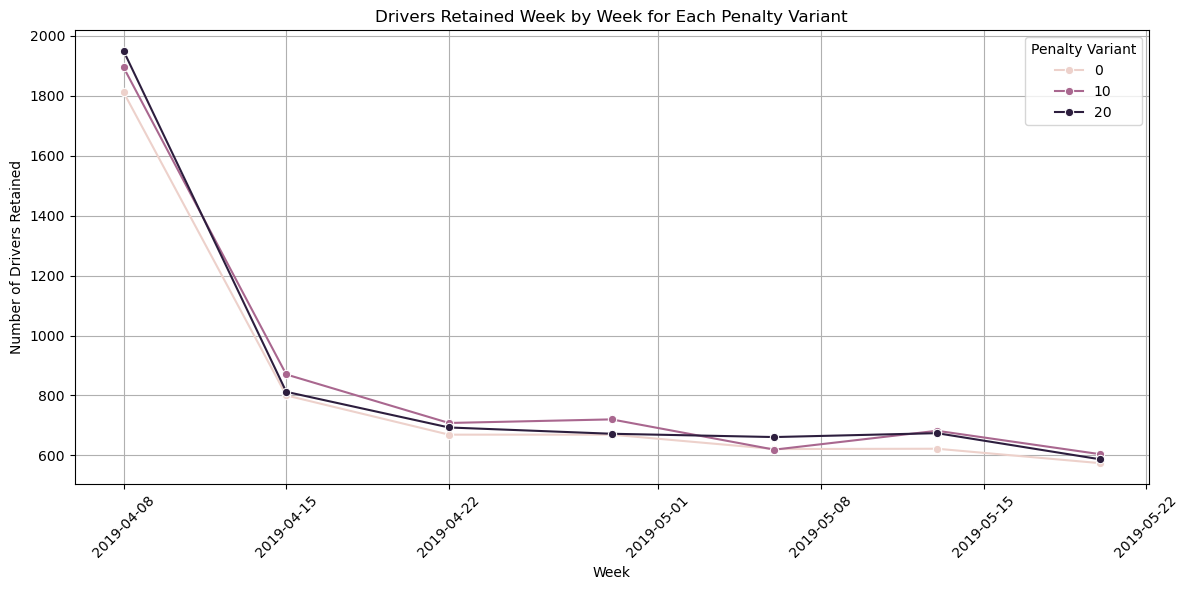

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


final_data['delivery_completed_time'] = pd.to_datetime(final_data['delivery_completed_time'])

final_data['week'] = final_data['delivery_completed_time'].dt.to_period('W')


driver_first_week = final_data.groupby('driver_id')['week'].min().reset_index()
driver_first_week.columns = ['driver_id', 'first_week']


if 'first_week' in final_data.columns:
    final_data = final_data.drop(columns=['first_week'])

final_data = final_data.merge(driver_first_week, on='driver_id')

# Filter drivers who started in the first week
first_week = final_data['week'].min()
active_drivers = final_data[final_data['first_week'] == first_week]

results_retention = []


for penalty_variant, group_data in active_drivers.groupby('penalty_variant'):
 
    week_1_drivers = set(group_data['driver_id'])
    week_by_week_counts = {}
    
    for week in pd.period_range(first_week.start_time, final_data['week'].max().start_time, freq='W'):
        week_data = final_data[
            (final_data['penalty_variant'] == penalty_variant) & 
            (final_data['delivery_completed_time'].dt.to_period('W') == week)
        ]
        current_week_drivers = set(week_data['driver_id'])
        retained_drivers = week_1_drivers & current_week_drivers
        week_by_week_counts[week] = len(retained_drivers)
    
    
    for week, count in week_by_week_counts.items():
        results_retention.append({'penalty_variant': penalty_variant, 'week': week, 'drivers_retained': count})

results_retention_df = pd.DataFrame(results_retention)


results_retention_df['week'] = results_retention_df['week'].apply(lambda x: x.start_time)

# Plota
plt.figure(figsize=(12, 6))
sns.lineplot(data=results_retention_df, x='week', y='drivers_retained', hue='penalty_variant', marker='o')
plt.title('Drivers Retained Week by Week for Each Penalty Variant')
plt.xlabel('Week')
plt.ylabel('Number of Drivers Retained')
plt.xticks(rotation=45)
plt.legend(title='Penalty Variant')
plt.grid(True)
plt.tight_layout()
plt.show()


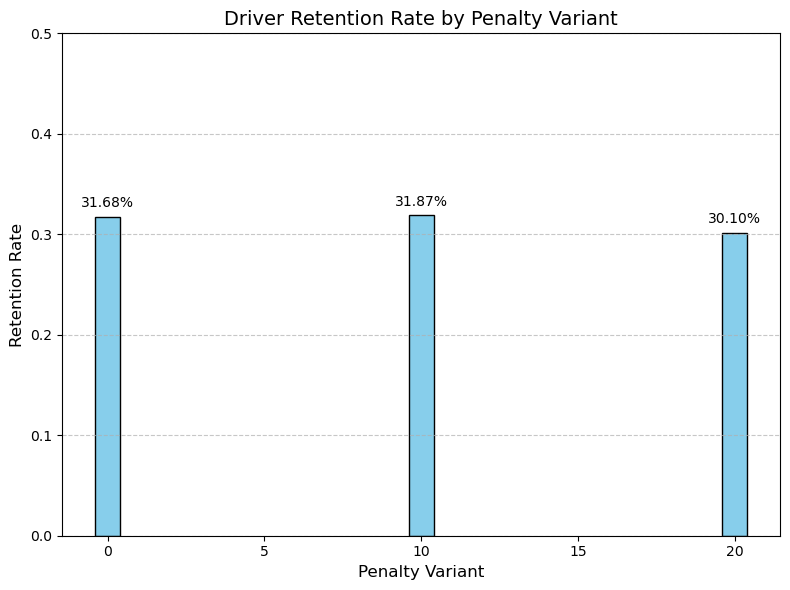

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


final_data['delivery_completed_time'] = pd.to_datetime(final_data['delivery_completed_time'])


final_data['week'] = final_data['delivery_completed_time'].dt.to_period('W')


driver_first_week = final_data.groupby('driver_id')['week'].min().reset_index()
driver_first_week.columns = ['driver_id', 'first_week']


if 'first_week' in final_data.columns:
    final_data = final_data.drop(columns=['first_week'])


final_data = final_data.merge(driver_first_week, on='driver_id')


first_week = final_data['week'].min()
active_drivers = final_data[final_data['first_week'] == first_week]


results_retention = []


for penalty_variant, group_data in active_drivers.groupby('penalty_variant'):
    # Get unique drivers in week 1
    week_1_drivers = set(group_data['driver_id'])
    total_first_drivers = len(week_1_drivers)
    
    
    last_week = final_data['week'].max()
    last_week_data = final_data[
        (final_data['penalty_variant'] == penalty_variant) & 
        (final_data['week'] == last_week)
    ]
    last_week_drivers = set(last_week_data['driver_id'])
    retained_drivers = week_1_drivers & last_week_drivers
    
    # Calculate retention rate
    retention_rate = len(retained_drivers) / total_first_drivers if total_first_drivers > 0 else 0
    results_retention.append({
        'penalty_variant': penalty_variant,
        'total_first_drivers': total_first_drivers,
        'total_last_drivers': len(last_week_drivers),
        'retained_drivers': len(retained_drivers),
        'retention_rate': retention_rate
    })


driver_comparison = pd.DataFrame(results_retention)


plt.figure(figsize=(8, 6))
bars = plt.bar(
    driver_comparison['penalty_variant'],
    driver_comparison['retention_rate'],
    color='skyblue',
    edgecolor='black'
)


for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2%}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5),  # Vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10)


plt.title('Driver Retention Rate by Penalty Variant', fontsize=14)
plt.xlabel('Penalty Variant', fontsize=12)
plt.ylabel('Retention Rate', fontsize=12)
plt.ylim(0, 0.5)  
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
